# Hermiticity and complete positivity

This file runs the same time-domain pipeline as
`DensityTimeSpectra`, but returns the density matrices $\rho(t)$ instead of the spectrum.
`example_1.py` and `example_2.py` reproduce the article examples for a single crystal
orientation at the resonance field.

Four evolutions are compared: the full one (Hamiltonian, microwave, relaxation;
`coherent=True`) and the relaxation superoperator alone, $\exp(Rt)$ (`coherent=False`),
each with and without the secular approximation (`secular=True/False`).

Hermiticity is measured as $\max|\rho_{ab}(t)-\rho^{*}_{ba}(t)|$, starting from the
context state (`initial_state="context"`).

Complete positivity is checked by the Choi criterion (M.-D. Choi, Linear Algebra Appl.
10, 285 (1975)). The system is formally entangled with an identical copy,
$\frac{1}{N}\sum_{ij}|i\rangle\langle j|\otimes|i\rangle\langle j|$, and only the system
evolves.

The joint matrix is assembled from the evolved matrix units $|i\rangle\langle j|$
(`initial_state="basis"`); the evolution is completely positive if its smallest
eigenvalue stays $\geq 0$.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

import example_1
import example_2

cases = [(False, True), (True, True), (False, False), (True, False)]  # (secular, coherent)


def evolve(example, secular, coherent, initial_state, **kwargs):
    out = example.build_example(secular=secular, coherent=coherent, initial_state=initial_state, **kwargs)
    creator = out["creator"]
    return out, creator(out["sample"], out["fields"], out["time"])


def hermiticity(density):
    dev = (density - density.conj().transpose(-2, -1)).abs()
    return dev.reshape(dev.shape[0], -1).amax(-1).numpy()


def smallest_joint_eigenvalue(maps):
    n = maps.shape[-1]
    m = maps.reshape(*maps.shape[:-3], n, n, n, n)
    joint = m.permute(*range(m.ndim - 4), -2, -4, -1, -3).reshape(*maps.shape[:-3], n * n, n * n) / n
    ev = torch.linalg.eigvalsh(0.5 * (joint + joint.conj().transpose(-2, -1)))[..., 0]
    return ev.reshape(ev.shape[0], -1).amin(-1).numpy()


def compute(example, **kwargs):
    results = {}
    for secular, coherent in cases:
        e, rho = evolve(example, secular, coherent, "context", **kwargs)
        _, maps = evolve(example, secular, coherent, "basis", **kwargs)
        results[(secular, coherent)] = {"time": e["time"], "res_fields": rho["res_fields"],
                                        "density": rho["density"], "maps": maps["density"]}
    results["title"] = e["title"]
    return results


def plot(results, fname=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    for secular, coherent in cases:
        r = results[(secular, coherent)]
        t = r["time"].numpy() * 1e6
        ls = "-" if secular else "--"
        color = "C0" if coherent else "C3"
        name = ("secular" if secular else "non-secular") + (", full" if coherent else ", R only")
        ax1.semilogx(t, np.maximum(hermiticity(r["density"]), 1e-21), ls, color=color, label=name)
        ax2.semilogx(t, smallest_joint_eigenvalue(r["maps"]), ls, color=color, label=name)

    ax1.set(yscale="log", ylim=(1e-22, 2e-15), xlabel="t (µs)",
            ylabel=r"max $|\rho_{ab}-\rho^{*}_{ba}|$", title="Hermiticity")
    ax2.axhline(0, color="k", lw=0.8)
    ax2.set_yscale("symlog", linthresh=1e-8)
    ax2.set(xlabel="t (µs)", ylabel=r"$\lambda_{\min}$", title="Complete positivity")

    for ax in (ax1, ax2):
        ax.legend()
    fig.suptitle(results["title"])
    fig.tight_layout()
    if fname is not None:
        fig.savefig(fname, format="png")
        fig.savefig(fname, format="eps")
    plt.show()

## Example 1: CT and LE triplets + singlet

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


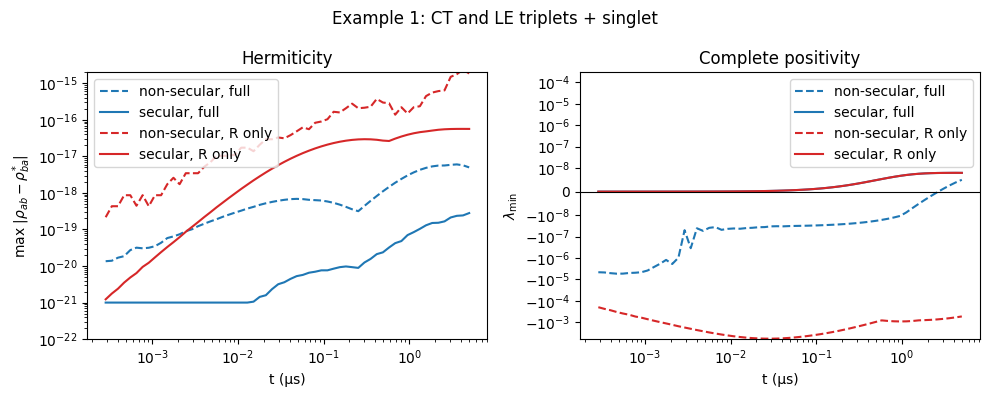

In [2]:
results_1 = compute(example_1)
plot(results_1, "example1_properties")
plt.show()

## Example 2: doublet–triplet complex

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


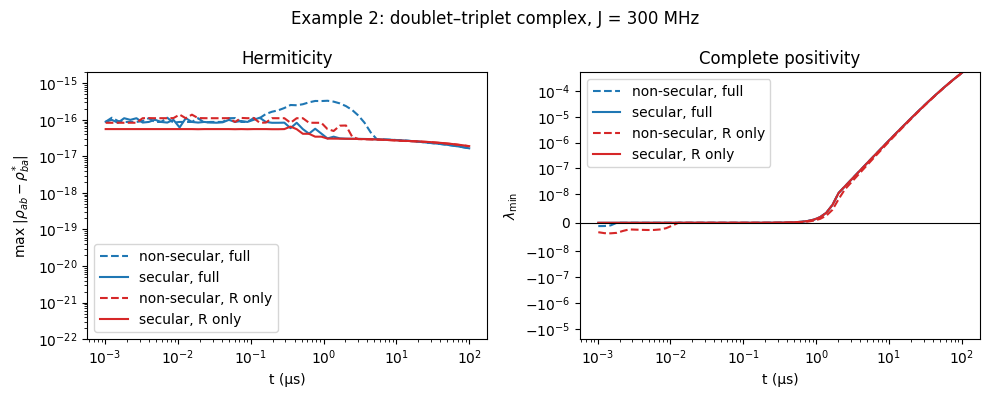

In [3]:
results_2 = compute(example_2)
plot(results_2, "example2_properties")
plt.show()